# 11 · Model Evaluation and Comparison

**What this notebook covers**

- Load the eligible models from the validation gate
- Compare CV scores (mean ± SD) on Train
- Confirm on Dev with bootstrap confidence intervals
- Precision-recall curves
- Day-zero vs full-lifecycle comparison
- Corrected t-test between models
- Apply the selection rule and save the decision

## 1. Environment setup
### 1.1 Imports

In [1]:
import hashlib
import json
import platform
import sys
from datetime import datetime, timezone
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score, brier_score_loss,
    confusion_matrix, f1_score, log_loss, precision_recall_curve, precision_score,
    recall_score, roc_auc_score, roc_curve,
)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)

### 1.2 Configuration: selection policy (pre-registered)
The selection rule is fixed **before** looking at results and is stored verbatim in the
output artifact.

In [2]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

NOTEBOOK_PREFIX = "11"
N_BOOTSTRAP = 2000
DEFAULT_THRESHOLD = 0.5   # only for threshold-dependent metrics here; the operating threshold is set in notebook 12

SELECTION_POLICY = {
    "preferred_variant": "day_zero",          # docs/05 section 5.4 (1): no-leakage variant for deployment
    "primary_metric": "pr_auc",               # decision #10
    "tolerance": "max(best model CV SD, 0.005)",
    "tie_breaker": "most interpretable model within tolerance",
    "interpretability_rank": {"logreg": 1, "decision_tree": 2, "random_forest": 3, "xgboost": 4, "svm_rbf": 5},
    "must_beat_baseline": "dummy_stratified__baseline on CV PR-AUC",
}
SELECTION_POLICY

{'preferred_variant': 'day_zero',
 'primary_metric': 'pr_auc',
 'tolerance': 'max(best model CV SD, 0.005)',
 'tie_breaker': 'most interpretable model within tolerance',
 'interpretability_rank': {'logreg': 1,
  'decision_tree': 2,
  'random_forest': 3,
  'xgboost': 4,
  'svm_rbf': 5},
 'must_beat_baseline': 'dummy_stratified__baseline on CV PR-AUC'}

### 1.3 Project paths, shared helpers and plotting style

In [3]:
# Resolve the repository root regardless of where the kernel was started
# (VS Code starts kernels in notebooks/, Jupyter may start them at the repo root).
def find_project_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "docs" / "DECISIONS.md").exists() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("Project root not found (no DECISIONS.md in any parent directory).")


PROJECT_ROOT = find_project_root()

PATHS = {
    "raw": PROJECT_ROOT / "data" / "hotel_bookings.csv",
    "clean": PROJECT_ROOT / "data" / "interim" / "hotel_bookings_clean.csv",
    "splits": PROJECT_ROOT / "data" / "processed" / "splits",
    "features": PROJECT_ROOT / "data" / "processed" / "features",
    "artifacts": PROJECT_ROOT / "artifacts",
    "preprocessors": PROJECT_ROOT / "artifacts" / "preprocessors",
    "model_outputs": PROJECT_ROOT / "artifacts" / "model_outputs",
    "models": PROJECT_ROOT / "models",
    "figures": PROJECT_ROOT / "reports" / "figures",
    "tables": PROJECT_ROOT / "reports" / "tables",
    "notebooks": PROJECT_ROOT / "notebooks",
}
for key in ("artifacts", "preprocessors", "model_outputs", "models", "figures", "tables"):
    PATHS[key].mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")

Project root: /home/hasitha-erandika/Documents/Projects/hotel-booking-cancellation-ml


In [4]:
# Columns that must always be treated as categorical strings when re-reading CSVs.
STRING_COLUMNS = [
    "hotel", "arrival_date_month", "meal", "country", "market_segment", "distribution_channel",
    "reserved_room_type", "assigned_room_type", "deposit_type", "agent", "company",
    "customer_type", "arrival_season",
]
TARGET = "is_canceled"
ID_COLUMN = "booking_id"
LEAKAGE_COLUMNS = ["reservation_status", "reservation_status_date"]

def sha256_file(path: Path, chunk_size: int = 1 << 20) -> str:
    """Streaming SHA-256 of a file (used to fingerprint every artifact)."""
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def save_json(obj: dict, path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, indent=2, default=str))


def load_json(path: Path) -> dict:
    if not path.exists():
        raise FileNotFoundError(f"Required artifact missing: {path.relative_to(PROJECT_ROOT)}")
    return json.loads(path.read_text())


def read_frame(path: Path) -> pd.DataFrame:
    """Read a project CSV with categorical columns forced to plain Python strings.

    `keep_default_na=False` + an explicit NA list stops pandas from turning legitimate
    category labels into NaN; numeric columns are parsed normally.
    """
    if not path.exists():
        raise FileNotFoundError(f"Required data file missing: {path.relative_to(PROJECT_ROOT)}")
    frame = pd.read_csv(
        path,
        dtype={col: object for col in STRING_COLUMNS},
        keep_default_na=False,
        na_values=["", "NaN", "nan"],
    )
    present = [c for c in STRING_COLUMNS if c in frame.columns]
    frame[present] = frame[present].astype(object)
    return frame

In [5]:
# One visual language for every figure in the project:
#  - blue = not cancelled, orange = cancelled (validated colour-blind-safe pair)
#  - single-series charts use blue; recessive grey grid; no top/right spines; no dual axes.
COLORS = {
    "not_canceled": "#2a78d6",
    "canceled": "#eb6834",
    "neutral": "#8a8985",
    "ink": "#0b0b0b",
    "ink_muted": "#52514e",
}
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQUENTIAL_CMAP = mpl.colors.LinearSegmentedColormap.from_list(
    "project_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
)
DIVERGING_CMAP = mpl.colors.LinearSegmentedColormap.from_list(
    "project_diverging", ["#2a78d6", "#e8e7e3", "#eb6834"]
)

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 110,
    "axes.prop_cycle": mpl.cycler(color=SERIES_COLORS),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae",
    "axes.labelcolor": COLORS["ink_muted"],
    "axes.titlesize": 13,
    "axes.titleweight": "semibold",
    "axes.titlecolor": COLORS["ink"],
    "axes.grid": True,
    "grid.color": "#e8e7e3",
    "grid.linewidth": 0.8,
    "xtick.color": COLORS["ink_muted"],
    "ytick.color": COLORS["ink_muted"],
    "lines.linewidth": 2,
    "legend.frameon": False,
})


def save_figure(fig, name: str) -> Path:
    """Save a figure under reports/figures with this notebook's numeric prefix."""
    path = PATHS["figures"] / f"{NOTEBOOK_PREFIX}_{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print(f"Saved figure -> {path.relative_to(PROJECT_ROOT)}")
    return path

## 2. Load the validation gate and eligible model outputs
Only models that passed every hard check in notebook 10 are evaluated. The gate report
must also be newer than every model card, so a model retrained after the gate cannot
slip through.

In [6]:
gate = load_json(PATHS["artifacts"] / "validation_gate_report.json")
assert gate["global_passed"], "Global validation checks failed - fix and re-run notebook 10."

ELIGIBLE = gate["eligible_models"]
if gate["ineligible_models"]:
    print("Excluded by the validation gate:", json.dumps(gate["ineligible_models"], indent=2))

cards, folds, dev_preds = {}, {}, {}
for model_id in ELIGIBLE:
    out_dir = PATHS["model_outputs"] / model_id
    card_path = out_dir / "model_card.json"
    assert sha256_file(card_path) == gate["model_card_hashes"][model_id], f"{model_id} changed after the gate - re-run notebook 10."
    cards[model_id] = load_json(card_path)
    folds[model_id] = pd.read_csv(out_dir / "cv_fold_scores.csv")
    dev_preds[model_id] = pd.read_csv(out_dir / "dev_predictions.csv")

reference_ids = dev_preds[ELIGIBLE[0]]["booking_id"]
assert all(p["booking_id"].equals(reference_ids) for p in dev_preds.values()), "Dev predictions are not row-aligned across models."
print(f"Evaluating {len(ELIGIBLE)} eligible models on {len(reference_ids):,} Dev rows.")

Evaluating 11 eligible models on 13,071 Dev rows.


## 3. The unified metric function
Every model goes through `evaluate_predictions`. This is the single source of metric
definitions for the project (docs/team/member-4 deliverable 2).

In [7]:
def evaluate_predictions(y_true, y_proba, threshold: float = DEFAULT_THRESHOLD) -> dict:
    y_true = np.asarray(y_true).astype(int)
    y_proba = np.clip(np.asarray(y_proba, dtype=float), 1e-7, 1 - 1e-7)
    y_pred = (y_proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "pr_auc": average_precision_score(y_true, y_proba),
        "roc_auc": roc_auc_score(y_true, y_proba),
        "brier": brier_score_loss(y_true, y_proba),
        "log_loss": log_loss(y_true, y_proba),
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "flag_rate": y_pred.mean(),
        "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn),
        "threshold": threshold,
    }

## 4. Primary comparison: CV mean ± SD on Train
This is the official comparison table (docs/06 §6.4). Variants are never mixed in one
row (validation-gate requirement). Models whose CV ran on a subsample are flagged.

In [8]:
CV_METRICS = ["pr_auc", "roc_auc", "f1", "precision", "recall", "balanced_accuracy", "accuracy", "brier"]
rows = []
for model_id, card in cards.items():
    f = folds[model_id]
    row = {"model_id": model_id, "model": card["model_key"], "variant": card["variant"],
           "cv_rows": card["cv"]["n_rows"], "cv_subsample": card["cv"]["n_rows"] != card["n_fit_rows"]}
    for metric in CV_METRICS:
        if metric in f:
            row[f"{metric}_mean"] = f[metric].mean()
            row[f"{metric}_std"] = f[metric].std(ddof=1)
    if "train_pr_auc" in f:
        row["overfit_gap_pr_auc"] = f["train_pr_auc"].mean() - f["pr_auc"].mean()
    rows.append(row)

cv_table = pd.DataFrame(rows).sort_values(["variant", "pr_auc_mean"], ascending=[True, False]).reset_index(drop=True)
cv_table.to_csv(PATHS["tables"] / "model_comparison_cv.csv", index=False)
cv_table.round(4)

,model_id,model,variant,cv_rows,cv_subsample,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std,f1_mean,f1_std,precision_mean,precision_std,recall_mean,recall_std,balanced_accuracy_mean,balanced_accuracy_std,accuracy_mean,accuracy_std,brier_mean,brier_std,overfit_gap_pr_auc
0,dummy_stratified__baseline,dummy_stratified,baseline,60996,False,0.2735,0.0013,0.5017,0.0031,0.2720,0.0045,0.2753,0.0046,0.2687,0.0045,0.5017,0.0031,0.6076,0.0024,0.3924,0.0024,-0.0020
1,dummy_most_frequent__baseline,dummy_most_frequent,baseline,60996,False,0.2728,0.0000,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000,0.7272,0.0000,0.2728,0.0000,0.0000
2,xgboost__day_zero,xgboost,day_zero,60996,False,0.7654,0.0023,0.8929,0.0012,0.6723,0.0033,0.7276,0.0043,0.6248,0.0083,0.7685,0.0028,0.8338,0.0007,0.1151,0.0007,0.1944
3,random_forest__day_zero,random_forest,day_zero,60996,False,0.7589,0.0046,0.8913,0.0021,0.6868,0.0021,0.6950,0.0073,0.6788,0.0052,0.7835,0.0013,0.8311,0.0022,0.1176,0.0011,0.2332
4,decision_tree__day_zero,decision_tree,day_zero,60996,False,0.7004,0.0026,0.8627,0.0015,0.6527,0.0036,0.5483,0.0040,0.8062,0.0117,0.7785,0.0036,0.7660,0.0027,0.1549,0.0014,0.0334
5,svm_rbf__day_zero,svm_rbf,day_zero,12000,True,0.6770,0.0140,0.8499,0.0084,0.6414,0.0115,0.5355,0.0082,0.7996,0.0187,0.7697,0.0104,0.7562,0.0070,NaN,NaN,0.0291
6,logreg__day_zero,logreg,day_zero,60996,False,0.6507,0.0060,0.8271,0.0030,0.5316,0.0093,0.6661,0.0059,0.4423,0.0103,0.6796,0.0053,0.7874,0.0030,0.1430,0.0011,0.0020
7,xgboost__full_lifecycle,xgboost,full_lifecycle,60996,False,0.8047,0.0025,0.9156,0.0007,0.7132,0.0015,0.7493,0.0045,0.6805,0.0061,0.7976,0.0017,0.8507,0.0005,0.1033,0.0005,0.1569
8,random_forest__full_lifecycle,random_forest,full_lifecycle,60996,False,0.7930,0.0041,0.9121,0.0014,0.7234,0.0052,0.7129,0.0076,0.7341,0.0036,0.8116,0.0032,0.8468,0.0034,0.1069,0.0009,0.1967
9,decision_tree__full_lifecycle,decision_tree,full_lifecycle,60996,False,0.7448,0.0053,0.8889,0.0012,0.6887,0.0030,0.5884,0.0047,0.8302,0.0050,0.8062,0.0022,0.7953,0.0029,0.1386,0.0005,0.0560


### 4.1 Visual comparison of CV PR-AUC
Dot = mean, whisker = ±1 SD across folds. Day-zero and full-lifecycle are two series on
one shared axis. The dashed line is the no-skill baseline.
Rows are sorted by the day-zero score, which is the variant the selection rule uses.
Models whose CV ran on a subsample have a hollow marker and a `*` in their label.

**How to run:** to refresh this chart, run sections 1 to 4 only. Section 10 rewrites
`model_selection.json`, which notebook 14 has locked.

Saved figure -> reports/figures/11_cv_pr_auc_comparison.png


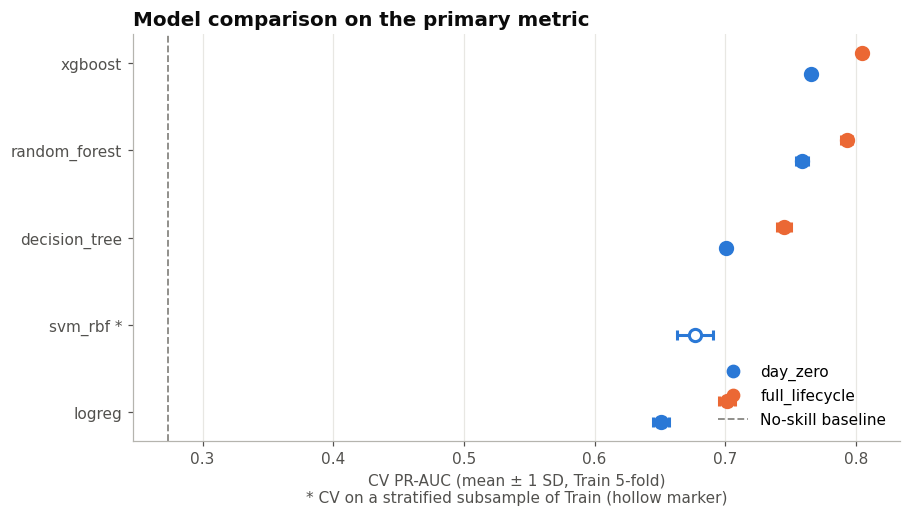

In [9]:
non_baseline = cv_table[cv_table["variant"] != "baseline"]
day_zero_scores = non_baseline[non_baseline["variant"] == "day_zero"].set_index("model")["pr_auc_mean"]
models_order = day_zero_scores.reindex(non_baseline["model"].unique()).sort_values(na_position="first").index.tolist()
subsampled = set(non_baseline.loc[non_baseline["cv_subsample"], "model"])
baseline_pr = cv_table.loc[cv_table["model_id"] == "dummy_stratified__baseline", "pr_auc_mean"]

fig, ax = plt.subplots(figsize=(9, 0.6 * len(models_order) + 1.8))
offsets = {"day_zero": -0.12, "full_lifecycle": 0.12}
for color, variant in zip(SERIES_COLORS, ["day_zero", "full_lifecycle"]):
    subset = non_baseline[non_baseline["variant"] == variant].set_index("model").reindex(models_order).dropna(subset=["pr_auc_mean"])
    for model_name, row in subset.iterrows():
        hollow = bool(row["cv_subsample"])
        ax.errorbar(row["pr_auc_mean"], models_order.index(model_name) + offsets[variant], xerr=row["pr_auc_std"],
                    fmt="o", markersize=8, color=color, ecolor=color, elinewidth=2, capsize=3,
                    markerfacecolor="white" if hollow else color, markeredgewidth=2)
    ax.plot([], [], "o", markersize=8, color=color, label=variant)
if len(baseline_pr):
    ax.axvline(baseline_pr.iloc[0], color=COLORS["neutral"], linestyle="--", linewidth=1.2, label="No-skill baseline")
ax.set_yticks(range(len(models_order)), [f"{m} *" if m in subsampled else m for m in models_order])
xlabel = "CV PR-AUC (mean ± 1 SD, Train 5-fold)"
if subsampled:
    xlabel += "\n* CV on a stratified subsample of Train (hollow marker)"
ax.set_xlabel(xlabel)
ax.set_title("Model comparison on the primary metric", loc="left")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
save_figure(fig, "cv_pr_auc_comparison")
plt.show()

## 5. Confirmation on Dev with bootstrap confidence intervals
Point estimates on ~13K rows still carry sampling noise. The percentile bootstrap
(2,000 resamples, seed 42) gives a 95 % CI for PR-AUC and ROC-AUC on Dev.

> Dev caveat: XGBoost used Dev for early stopping, so its Dev score is slightly optimistic.

In [10]:
y_dev = dev_preds[ELIGIBLE[0]]["y_true"].to_numpy()


def bootstrap_ci(y_true, y_proba, metric, n_boot: int = N_BOOTSTRAP, alpha: float = 0.05, seed: int = RANDOM_STATE):
    """Percentile bootstrap. A fixed seed regenerates the *same* resamples for every model,
    so per-resample differences between two models are paired."""
    rng = np.random.default_rng(seed)
    n = len(y_true)
    values = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, n, size=n)
        values[b] = metric(y_true[idx], y_proba[idx])
    return np.quantile(values, [alpha / 2, 1 - alpha / 2]), values


dev_rows, BOOT_PR_AUC = [], {}
for model_id in ELIGIBLE:
    proba = dev_preds[model_id]["y_proba"].to_numpy()
    metrics = evaluate_predictions(y_dev, proba)
    (pr_lo, pr_hi), BOOT_PR_AUC[model_id] = bootstrap_ci(y_dev, proba, average_precision_score)
    (roc_lo, roc_hi), _ = bootstrap_ci(y_dev, proba, roc_auc_score)
    dev_rows.append({"model_id": model_id, "variant": cards[model_id]["variant"], **metrics,
                     "pr_auc_ci_low": pr_lo, "pr_auc_ci_high": pr_hi, "roc_auc_ci_low": roc_lo, "roc_auc_ci_high": roc_hi})

dev_table = pd.DataFrame(dev_rows).sort_values("pr_auc", ascending=False).reset_index(drop=True)
dev_table.to_csv(PATHS["tables"] / "model_comparison_dev.csv", index=False)
dev_table[["model_id", "pr_auc", "pr_auc_ci_low", "pr_auc_ci_high", "roc_auc", "brier", "precision", "recall", "f1", "accuracy"]].round(4)

,model_id,pr_auc,pr_auc_ci_low,pr_auc_ci_high,roc_auc,brier,precision,recall,f1,accuracy
0,xgboost__full_lifecycle,0.8124,0.8011,0.8243,0.9176,0.1017,0.7483,0.6912,0.7186,0.8523
1,random_forest__full_lifecycle,0.8008,0.7883,0.8138,0.9139,0.1060,0.7108,0.7487,0.7292,0.8484
2,xgboost__day_zero,0.7707,0.7579,0.7840,0.8940,0.1143,0.7218,0.6376,0.6771,0.8341
3,random_forest__day_zero,0.7632,0.7496,0.7772,0.8910,0.1182,0.6842,0.7032,0.6936,0.8305
4,decision_tree__full_lifecycle,0.7534,0.7397,0.7672,0.8889,0.1398,0.5780,0.8421,0.6855,0.7892
5,decision_tree__day_zero,0.7088,0.6940,0.7239,0.8654,0.1546,0.5474,0.8151,0.6549,0.7657
6,logreg__full_lifecycle,0.7030,0.6886,0.7181,0.8640,0.1293,0.6869,0.5464,0.6087,0.8084
7,svm_rbf__day_zero,0.6887,0.6730,0.7042,0.8571,0.1321,0.6682,0.5846,0.6236,0.8075
8,logreg__day_zero,0.6507,0.6357,0.6664,0.8267,0.1430,0.6557,0.4583,0.5395,0.7866
9,dummy_most_frequent__baseline,0.2727,0.2651,0.2805,0.5000,0.2727,0.0000,0.0000,0.0000,0.7273


## 6. Curves on Dev (day-zero models)
### 6.1 Precision–recall curves
PR curves are the most informative view under class imbalance: each curve shows the
precision achievable at each recall level. The dashed line is prevalence (no skill).

Saved figure -> reports/figures/11_pr_roc_curves_dev.png


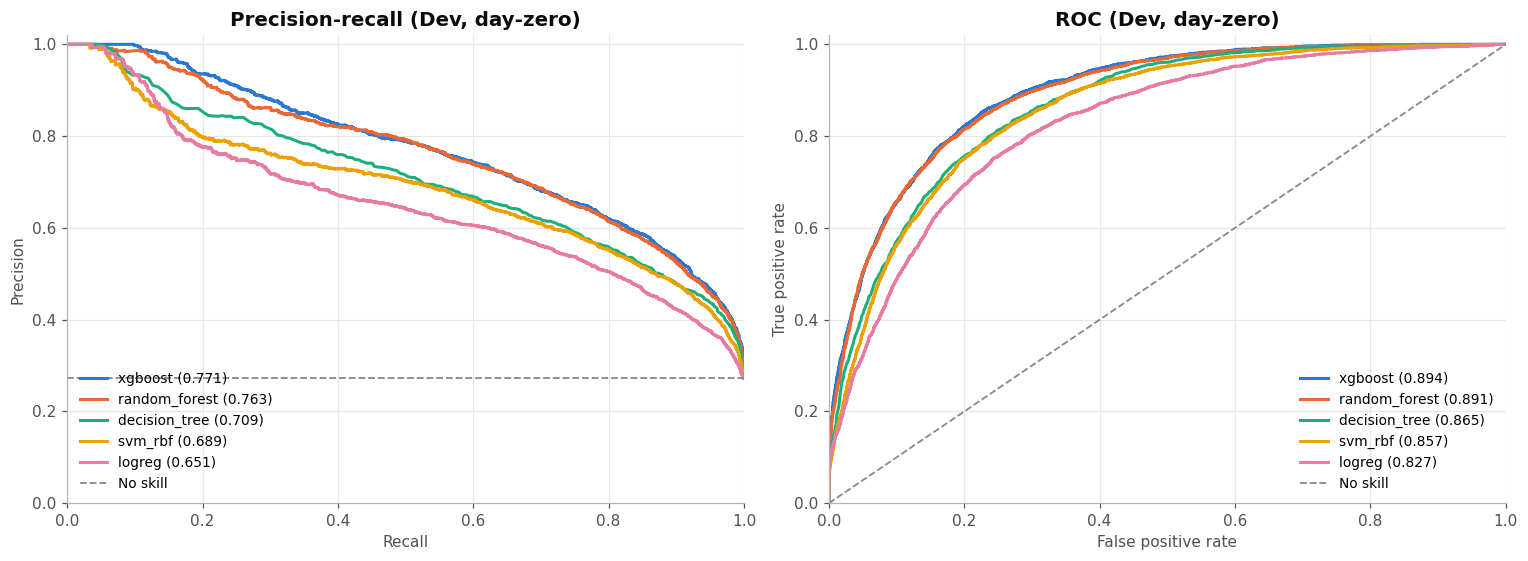

In [11]:
day_zero_ids = [m for m in ELIGIBLE if cards[m]["variant"] == "day_zero"]
day_zero_ids = sorted(day_zero_ids, key=lambda m: -dev_table.set_index("model_id").loc[m, "pr_auc"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for color, model_id in zip(SERIES_COLORS, day_zero_ids):
    proba = dev_preds[model_id]["y_proba"]
    precision, recall, _ = precision_recall_curve(y_dev, proba)
    fpr, tpr, _ = roc_curve(y_dev, proba)
    label = f"{cards[model_id]['model_key']} ({average_precision_score(y_dev, proba):.3f})"
    axes[0].plot(recall, precision, color=color, label=label)
    axes[1].plot(fpr, tpr, color=color, label=f"{cards[model_id]['model_key']} ({roc_auc_score(y_dev, proba):.3f})")
axes[0].axhline(y_dev.mean(), color=COLORS["neutral"], linestyle="--", linewidth=1.2, label="No skill")
axes[1].plot([0, 1], [0, 1], color=COLORS["neutral"], linestyle="--", linewidth=1.2, label="No skill")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Precision-recall (Dev, day-zero)")
axes[1].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC (Dev, day-zero)")
for ax in axes:
    ax.legend(loc="lower left" if ax is axes[0] else "lower right", fontsize=9)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
fig.tight_layout()
save_figure(fig, "pr_roc_curves_dev")
plt.show()

## 7. Day-zero vs full-lifecycle: how much signal comes from post-booking fields?
docs/06 §6.7 requires this delta to be reported openly, not hidden behind the
better-looking number. A large gain means post-booking events carry much of the signal.
That is useful for a *re-scoring* use case, but not available at booking time.

In [12]:
pivot = cv_table[cv_table["variant"].isin(["day_zero", "full_lifecycle"])].pivot_table(
    index="model", columns="variant", values="pr_auc_mean")
if {"day_zero", "full_lifecycle"} <= set(pivot.columns):
    pivot["delta_pr_auc"] = pivot["full_lifecycle"] - pivot["day_zero"]
    pivot["relative_gain_pct"] = pivot["delta_pr_auc"] / pivot["day_zero"] * 100
pivot.round(4)

variant,day_zero,full_lifecycle,delta_pr_auc,relative_gain_pct
model,,,,
decision_tree,0.7004,0.7448,0.0444,6.3343
logreg,0.6507,0.7013,0.0506,7.7737
random_forest,0.7589,0.7930,0.0341,4.4947
svm_rbf,0.6770,NaN,NaN,NaN
xgboost,0.7654,0.8047,0.0393,5.1330


## 8. Statistical comparison: Nadeau–Bengio corrected resampled t-test
Fold scores from k-fold CV are **not independent**: training sets overlap. The naive
paired t-test is therefore over-confident. The Nadeau & Bengio (2003) correction inflates
the variance by `(1/k + n_test/n_train)`. Only models evaluated on the **same folds** are
compared (subsample-CV models are skipped).

In [13]:
def corrected_resampled_ttest(scores_a, scores_b, n_train: int, n_test: int):
    diff = np.asarray(scores_a) - np.asarray(scores_b)
    k = len(diff)
    mean, var = diff.mean(), diff.var(ddof=1)
    if var == 0:
        return mean, np.inf, 0.0
    t_stat = mean / np.sqrt((1 / k + n_test / n_train) * var)
    p_value = 2 * stats.t.sf(abs(t_stat), df=k - 1)
    return mean, t_stat, p_value


comparable = [m for m in day_zero_ids if not cv_table.set_index("model_id").loc[m, "cv_subsample"]]
n_cv_rows = cards[comparable[0]]["cv"]["n_rows"] if comparable else 0
k_folds = cards[comparable[0]]["cv"]["n_splits"] if comparable else 5
ttests = []
for i, a in enumerate(comparable):
    for b in comparable[i + 1:]:
        mean_diff, t_stat, p_value = corrected_resampled_ttest(folds[a]["pr_auc"], folds[b]["pr_auc"],
                                                              n_train=n_cv_rows * (k_folds - 1) // k_folds,
                                                              n_test=n_cv_rows // k_folds)
        ttests.append({"model_a": a, "model_b": b, "mean_diff_pr_auc": mean_diff, "t": t_stat, "p_value": p_value})
ttest_table = pd.DataFrame(ttests).sort_values("p_value") if ttests else pd.DataFrame()
ttest_table.to_csv(PATHS["tables"] / "11_corrected_ttests.csv", index=False)
ttest_table.round(4)

,model_a,model_b,mean_diff_pr_auc,t,p_value
2,xgboost__day_zero,logreg__day_zero,0.1147,23.9455,0.0000
1,xgboost__day_zero,decision_tree__day_zero,0.0650,20.2394,0.0000
4,random_forest__day_zero,logreg__day_zero,0.1082,17.3965,0.0001
5,decision_tree__day_zero,logreg__day_zero,0.0497,14.3489,0.0001
3,random_forest__day_zero,decision_tree__day_zero,0.0585,12.9474,0.0002
0,xgboost__day_zero,random_forest__day_zero,0.0065,2.7066,0.0537


## 9. Apply the pre-registered selection rule
1. Candidates = eligible, `preferred_variant`, not a baseline.
2. Best = highest CV PR-AUC. Tolerance = max(best SD, 0.005).
3. Among candidates within tolerance of the best, choose the **most interpretable**.
4. The choice must beat the stratified-dummy baseline.

In [14]:
policy = SELECTION_POLICY
candidates = cv_table[(cv_table["variant"] == policy["preferred_variant"])].copy()
best_row = candidates.loc[candidates["pr_auc_mean"].idxmax()]
tolerance = max(float(best_row["pr_auc_std"]), 0.005)

candidates["within_tolerance"] = candidates["pr_auc_mean"] >= best_row["pr_auc_mean"] - tolerance
candidates["interpretability_rank"] = candidates["model"].map(policy["interpretability_rank"])
shortlist = candidates[candidates["within_tolerance"]].sort_values(["interpretability_rank", "pr_auc_mean"], ascending=[True, False])
selected = shortlist.iloc[0]

baseline_score = float(baseline_pr.iloc[0]) if len(baseline_pr) else float(y_dev.mean())
assert selected["pr_auc_mean"] > baseline_score, "Selected model does not beat the no-skill baseline."

print(f"Best CV PR-AUC: {best_row['model_id']} = {best_row['pr_auc_mean']:.4f} (SD {best_row['pr_auc_std']:.4f})")
print(f"Tolerance: {tolerance:.4f} -> shortlist {shortlist['model_id'].tolist()}")
print(f"SELECTED: {selected['model_id']}")
candidates[["model_id", "pr_auc_mean", "pr_auc_std", "within_tolerance", "interpretability_rank"]].round(4)

Best CV PR-AUC: xgboost__day_zero = 0.7654 (SD 0.0023)
Tolerance: 0.0050 -> shortlist ['xgboost__day_zero']
SELECTED: xgboost__day_zero


,model_id,pr_auc_mean,pr_auc_std,within_tolerance,interpretability_rank
2,xgboost__day_zero,0.7654,0.0023,True,4
3,random_forest__day_zero,0.7589,0.0046,False,3
4,decision_tree__day_zero,0.7004,0.0026,False,2
5,svm_rbf__day_zero,0.6770,0.0140,False,5
6,logreg__day_zero,0.6507,0.0060,False,1


### 9.1 Paired bootstrap: selected vs best-scoring model on Dev
If the rule picked a simpler model than the top scorer, how much PR-AUC is given up,
and is the gap distinguishable from noise? The bootstrap resamples are shared, so the
difference is paired.

In [15]:
if selected["model_id"] != best_row["model_id"]:
    diff = BOOT_PR_AUC[best_row["model_id"]] - BOOT_PR_AUC[selected["model_id"]]
    low, high = np.quantile(diff, [0.025, 0.975])
    print(f"Dev PR-AUC gap (best - selected): mean {diff.mean():.4f}, 95% CI [{low:.4f}, {high:.4f}]")
    print("Gap includes 0 -> not distinguishable from noise." if low <= 0 <= high else "Gap excludes 0 -> trade-off is real; document it.")
else:
    print("The most interpretable model within tolerance is also the top scorer.")

The most interpretable model within tolerance is also the top scorer.


## 10. Persist the selection decision

In [16]:
selection = {
    "created_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "notebook": "11_model_evaluation_comparison.ipynb",
    "policy": SELECTION_POLICY,
    "selected_model_id": selected["model_id"],
    "selected_model_path": cards[selected["model_id"]]["model_path"],
    "selected_cv_pr_auc": {"mean": float(selected["pr_auc_mean"]), "std": float(selected["pr_auc_std"])},
    "best_scoring_model_id": best_row["model_id"],
    "tolerance": tolerance,
    "shortlist": shortlist["model_id"].tolist(),
    "baseline_cv_pr_auc": baseline_score,
    "rationale": (f"{selected['model_id']} is the most interpretable {policy['preferred_variant']} model within "
                  f"{tolerance:.4f} CV PR-AUC of the best ({best_row['model_id']})."),
    "gate_report_created_at": gate["created_at"],
}
save_json(selection, PATHS["artifacts"] / "model_selection.json")
selection

{'created_at': '2026-10-12T03:14:28+00:00',
 'notebook': '11_model_evaluation_comparison.ipynb',
 'policy': {'preferred_variant': 'day_zero',
  'primary_metric': 'pr_auc',
  'tolerance': 'max(best model CV SD, 0.005)',
  'tie_breaker': 'most interpretable model within tolerance',
  'interpretability_rank': {'logreg': 1,
   'decision_tree': 2,
   'random_forest': 3,
   'xgboost': 4,
   'svm_rbf': 5},
  'must_beat_baseline': 'dummy_stratified__baseline on CV PR-AUC'},
 'selected_model_id': 'xgboost__day_zero',
 'selected_model_path': 'models/xgboost__day_zero.joblib',
 'selected_cv_pr_auc': {'mean': 0.7654160989884039,
  'std': 0.002298957093459008},
 'best_scoring_model_id': 'xgboost__day_zero',
 'tolerance': 0.005,
 'shortlist': ['xgboost__day_zero'],
 'baseline_cv_pr_auc': 0.2734578719154206,
 'rationale': 'xgboost__day_zero is the most interpretable day_zero model within 0.0050 CV PR-AUC of the best (xgboost__day_zero).',
 'gate_report_created_at': '2026-10-12T03:11:49+00:00'}

## 11. Interpretation notes for the report
Numbers from the recorded run (`reports/tables/model_comparison_cv.csv`,
`model_comparison_dev.csv`, `11_corrected_ttests.csv`).

- **Headline:** `xgboost__day_zero` is selected. CV PR-AUC 0.765 ± 0.002, which is
  2.8 times the no-skill baseline of 0.273. Dev PR-AUC 0.771 [0.758, 0.784].
- **Stability:** the CV SD of the winner is 0.0023, and the Dev CI is about 0.026 wide.
  The ranking of the day-zero models is the same on CV and Dev.
- **Leakage-timing delta (§7):** full-lifecycle models gain 0.034 to 0.051 PR-AUC
  (XGBoost: 0.805 vs 0.765). The gain is real but modest, and those models cannot score
  a booking on the day it is made.
- **Significance (§8):** every pair of day-zero models differs at p < 0.001 except
  XGBoost vs Random Forest (difference 0.0065, p = 0.054). Random Forest is the recorded
  fallback.
- **SVM:** scored on a 12,000-row CV subsample, so its CV number is noisier (SD 0.014)
  and not strictly comparable. It is excluded from the corrected t-test for that reason.
- Decision #27 in `DECISIONS.md` records the choice and cites `artifacts/model_selection.json`.